# Intrinsic and extrinsic scalar curvature by grid resolution

Run the shared setup cells first, then use the mathematical experiment sections below. Each section has one run cell and one plot cell, and keeps its own results. Plots use one color per manifold: circles for intrinsic curvature, squares for extrinsic curvature, and a dotted line for method disagreement. The irregular-grid duplicates have been removed.

The 2D section contains sphere, ellipsoid and hyperboloid cases. `INCLUDE_TOTAL_TEST_GRID` adds the two 10,223 × 10,344 grids to that section. The 3D and 4D section contains the slow analytic tests; use `INCLUDE_SLOW_TESTS` and `SLOW_CASE_NAMES` to enable/select them. These grids can require several gigabytes of memory, particularly the ambient-4096 ellipsoid and 119-million-point 4D sphere. Each slow schedule ends at its corresponding test maximum. Run only the section you want to investigate.

The final section contains quartic, Gaussian and rippled graph surfaces on nonperiodic `[-1, 1]²` grids, with analytic curvature references and schedules ending at 512 samples per axis. Both methods always receive the same embedding, spacings, patches and device. Random isometry is controlled by `APPLY_RANDOM_ISOMETRY`. Outputs from the former combined sweep have been cleared so they are not mistaken for results of the new sections.


The image dataset section at the end adds independent dSprites and COIL-20 sub-grid comparisons of signed mean curvature and runtime, without analytic ground truth.

In [73]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import torch

from microscope.computations_grid.curvature import scalar_curvature as intrinsic_curvature
from microscope.computations_grid.curvature_extrinsic import scalar_curvature as extrinsic_curvature
from microscope.cyclic_dimensions import get_difference_intervals
from microscope.manifold_examples.ellipsoid import ellipsoid_scalar_curvature
from microscope.manifold_examples.hyperboloid import hyperboloid_scalar_curvature
from microscope.manifold_examples.sphere import sphere_scalar_curvature
from microscope.manifold_examples.sampling_grid import sample_ellipsoid_on_grid, sample_hyperboloid_on_grid

DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
INCLUDE_TOTAL_TEST_GRID = True
N_SIZES = 10
INCLUDE_SLOW_TESTS = True
SLOW_CASE_NAMES = None  # None selects all; e.g. ["3D ellipsoid / ambient 4"].
DTYPE = np.float32  # Generate in float64; casting to float32 demonstrates roundoff.
APPLY_RANDOM_ISOMETRY = False
SEED = 0


In [74]:
# 2D quadric cases; irregular-grid duplicates are omitted.
CASES_2D = {
    "sphere": dict(kind="ellipsoid", axes=[2, 2, 2], maximum=(1006, 1000), patches=[56, 56], fraction=.8),
    "ellipsoid": dict(kind="ellipsoid", axes=[1, 1.5, 3], maximum=(1006, 1000), patches=[56, 56], fraction=.8),
    "hyperboloid": dict(kind="hyperboloid", axes=[5, 1, 3], maximum=(1006, 1000), patches=[56, 56]),
}
if INCLUDE_TOTAL_TEST_GRID:
    for name, axes in (("sphere / total-test grid", [2, 2, 2]),
                       ("ellipsoid / total-test grid", [1, 1.5, 3])):
        CASES_2D[name] = dict(kind="ellipsoid", axes=axes, maximum=(10223, 10344),
                             patches=[1034, 1042], fraction=.9999)

GRAPH_CASES = {
    name: dict(kind="graph", graph=graph, maximum=(512, 512), patches=[56, 56])
    for name, graph in (("quartic", "quartic"), ("Gaussian", "gaussian"), ("rippled", "rippled"))
}


def grid_sizes(maximum, count=N_SIZES):
    sizes = np.rint(np.geomspace(16, np.asarray(maximum), count)).astype(int)
    sizes[-1] = maximum
    assert len({tuple(pair) for pair in sizes}) == count
    return [tuple(pair) for pair in sizes]


# Exact slow-test axes, maxima, ambient dimensions, and patch sizes.
SLOW_CASE_SPECS = {}
for ambient in (4, 100, 4096):
    SLOW_CASE_SPECS[f"3D ellipsoid / ambient {ambient}"] = dict(
        kind="ellipsoid", axes=[1, 1.5, 3, 1.8], ambient=ambient,
        maximum=(56, 56, 50) if ambient > 100 else (106, 106, 100),
        patches=[16]*3, fraction=.8)
for ambient in (4, 100):
    SLOW_CASE_SPECS[f"3D hyperboloid / ambient {ambient}"] = dict(
        kind="hyperboloid", axes=[5, 1, 3, 1], ambient=ambient,
        maximum=(156, 156, 150), patches=[56]*3)
for ambient in (5, 10):
    SLOW_CASE_SPECS[f"4D sphere / ambient {ambient}"] = dict(
        kind="sphere", axes=[2]*5, ambient=ambient,
        maximum=(106, 106, 106, 100), patches=[16]*4, fraction=.8)
selected = list(SLOW_CASE_SPECS) if SLOW_CASE_NAMES is None else SLOW_CASE_NAMES
SLOW_CASES = ({name: SLOW_CASE_SPECS[name] for name in selected}
              if INCLUDE_SLOW_TESTS else {})


def graph_height_and_curvature(u, v, graph):
    # For X=(u,v,f(u,v)), R=2*(f_uu*f_vv-f_uv**2)/(1+f_u**2+f_v**2)**2.
    # Differentiate each explicit height analytically, independently of the stencil.
    if graph == "quartic":
        height = .2*u**4 + .3*v**4 + .1*u*v
        fu, fv = .8*u**3 + .1*v, 1.2*v**3 + .1*u
        fuu, fvv, fuv = 2.4*u**2, 3.6*v**2, .1
    elif graph == "gaussian":
        height = .7*np.exp(-2*(u*u + v*v))
        fu, fv = -4*u*height, -4*v*height
        fuu, fvv, fuv = (16*u*u - 4)*height, (16*v*v - 4)*height, 16*u*v*height
    elif graph == "rippled":
        height = .2*np.sin(2*u) + .15*np.cos(3*v) + .1*u*v
        fu, fv = .4*np.cos(2*u) + .1*v, -.45*np.sin(3*v) + .1*u
        fuu, fvv, fuv = -.8*np.sin(2*u), -1.35*np.cos(3*v), .1
    else:
        raise ValueError(f"Unknown graph: {graph}")
    truth = 2*(fuu*fvv - fuv**2)/(1 + fu**2 + fv**2)**2
    return height, truth


def sample_case(spec, sizes):
    dim = len(sizes)
    if spec["kind"] == "graph":
        coordinates = [np.linspace(-1., 1., num=n) for n in sizes]
        u, v = np.meshgrid(*coordinates, indexing="ij")
        height, truth = graph_height_and_curvature(u, v, spec["graph"])
        points = np.stack([u, v, height], axis=-1)
        if APPLY_RANDOM_ISOMETRY:
            # Fixed rigid transform across resolutions for comparable roundoff.
            rng = np.random.default_rng(SEED)
            rotation, _ = np.linalg.qr(rng.normal(size=(3, 3)))
            points = points @ rotation + rng.uniform(-1., 1., size=3)
        return (points.astype(DTYPE, copy=False), truth[3:-3, 3:-3],
                [2/(n - 1) for n in sizes], [])
    cyclic_dimensions = [dim - 1]
    ambient = spec.get("ambient", dim + 1)
    if APPLY_RANDOM_ISOMETRY:
        # The sampler's translation uses NumPy's global RNG, in addition to seed.
        np.random.seed(SEED)
    sampling = dict(semi_axes=spec["axes"], n_samples_per_dim=list(sizes),
                    ambient_space_dim=ambient,
                    apply_random_isometry=APPLY_RANDOM_ISOMETRY, seed=SEED)
    if spec["kind"] in ("ellipsoid", "sphere"):
        points, axes, phis, _ = sample_ellipsoid_on_grid(
            **sampling, fraction_of_angles=spec["fraction"])
        range_sizes = [(2*spec["fraction"] - 1)*np.pi]*(dim - 1) + [2*np.pi]
        truth = (sphere_scalar_curvature(float(axes[0]), phis)
                 if spec["kind"] == "sphere" else ellipsoid_scalar_curvature(axes, phis))
    else:
        points, axes, phis, _ = sample_hyperboloid_on_grid(**sampling)
        range_sizes = [2.]*(dim - 1) + [2*np.pi]
        truth = hyperboloid_scalar_curvature(axes, phis)
    crop = (slice(3, -3),)*(dim - 1) + (slice(None),)
    intervals = get_difference_intervals(list(sizes), range_sizes, cyclic_dimensions)
    return points.astype(DTYPE, copy=False), truth[crop], intervals, cyclic_dimensions


In [75]:
def compare_case_at_size(name, spec, sizes, device=DEVICE):
    points, truth, intervals, cyclic_dimensions = sample_case(spec, sizes)
    kwargs = dict(difference_intervals=intervals, cyclic_dimensions=cyclic_dimensions,
                  patch_sizes=spec["patches"], device=device)
    row = dict(case=name, shape=sizes, points=int(np.prod(sizes)),
               dtype=str(points.dtype), ambient=points.shape[-1], device=str(device))
    predictions = {}
    for label, method in (("intrinsic", intrinsic_curvature),
                          ("extrinsic", extrinsic_curvature)):
        if str(device).startswith("cuda"):
            torch.cuda.synchronize(device)
        start = perf_counter()
        predictions[label] = method(points, **kwargs)
        if str(device).startswith("cuda"):
            torch.cuda.synchronize(device)
        row[label + "_seconds"] = perf_counter() - start
        assert predictions[label].shape == truth.shape
        error = np.abs(predictions[label] - truth)
        row[label + "_mae"] = float(error.mean())
        row[label + "_max_error"] = float(error.max())
    row["method_mae"] = float(np.abs(predictions["intrinsic"] - predictions["extrinsic"]).mean())
    return row


def run_cases(case_specs, device=DEVICE):
    results = []
    for name, spec in case_specs.items():
        for sizes in grid_sizes(spec["maximum"]):
            input_gb = (int(np.prod(sizes))*spec.get("ambient", len(sizes) + 1)
                        * np.dtype(DTYPE).itemsize/1e9)
            print(f"Running {name}, {sizes}: embedding alone {input_gb:.3g} GB", flush=True)
            row = compare_case_at_size(name, spec, sizes, device=device)
            results.append(row)
            print(f"{name:27s} {sizes!s:15s}  intrinsic {row['intrinsic_mae']:.3g}  "
                  f"extrinsic {row['extrinsic_mae']:.3g}  difference {row['method_mae']:.3g}")
    return results


def plot_results(results, title):
    if not results:
        print(f"{title}: no results. Enable or select cases above, then run this section.")
        return None
    fig, axes = plt.subplots(2, 1, figsize=(13, 9), constrained_layout=True)
    names = list(dict.fromkeys(row["case"] for row in results))
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for index, name in enumerate(names):
        rows = sorted((row for row in results if row["case"] == name), key=lambda row: row["points"])
        x = [row["points"] for row in rows]
        color = colors[index % len(colors)]
        for method, marker, linestyle in (("intrinsic", "o", "-"), ("extrinsic", "s", "--")):
            style = dict(color=color, marker=marker, linestyle=linestyle, label=f"{name}: {method}")
            axes[0].loglog(x, [row[method + "_mae"] for row in rows], **style)
            axes[1].loglog(x, [row[method + "_seconds"] for row in rows], **style)
        axes[0].loglog(x, [row["method_mae"] for row in rows], ":", color=color,
                       label=f"{name}: difference", alpha=.65)
    axes[0].set(xlabel="grid points", ylabel="mean absolute scalar-curvature error",
                title="Analytic error and method agreement")
    axes[1].set(xlabel="grid points", ylabel="elapsed seconds", title="Runtime, including patches")
    fig.suptitle(title)
    for ax in axes:
        ax.grid(True, which="both", alpha=.25)
        ax.legend(fontsize=9, ncol=2)
    plt.show()
    return fig


## 2D manifolds

Sphere, ellipsoid and hyperboloid, with optional total-test grids.

In [76]:
results_2d = run_cases(CASES_2D)

Running sphere, (16, 16): embedding alone 3.07e-06 GB
sphere                      (16, 16)         intrinsic 0.00785  extrinsic 2.67e-07  difference 0.00785
Running sphere, (25, 25): embedding alone 7.5e-06 GB
sphere                      (25, 25)         intrinsic 0.00308  extrinsic 7.4e-07  difference 0.00308
Running sphere, (40, 40): embedding alone 1.92e-05 GB
sphere                      (40, 40)         intrinsic 0.00117  extrinsic 2.3e-06  difference 0.00117
Running sphere, (64, 63): embedding alone 4.84e-05 GB
sphere                      (64, 63)         intrinsic 0.000447  extrinsic 4.91e-06  difference 0.000447
Running sphere, (101, 101): embedding alone 0.000122 GB
sphere                      (101, 101)       intrinsic 0.000178  extrinsic 1.19e-05  difference 0.000178
Running sphere, (160, 159): embedding alone 0.000305 GB
sphere                      (160, 159)       intrinsic 8.09e-05  extrinsic 3.12e-05  difference 8.66e-05
Running sphere, (253, 252): embedding alone 0.00076

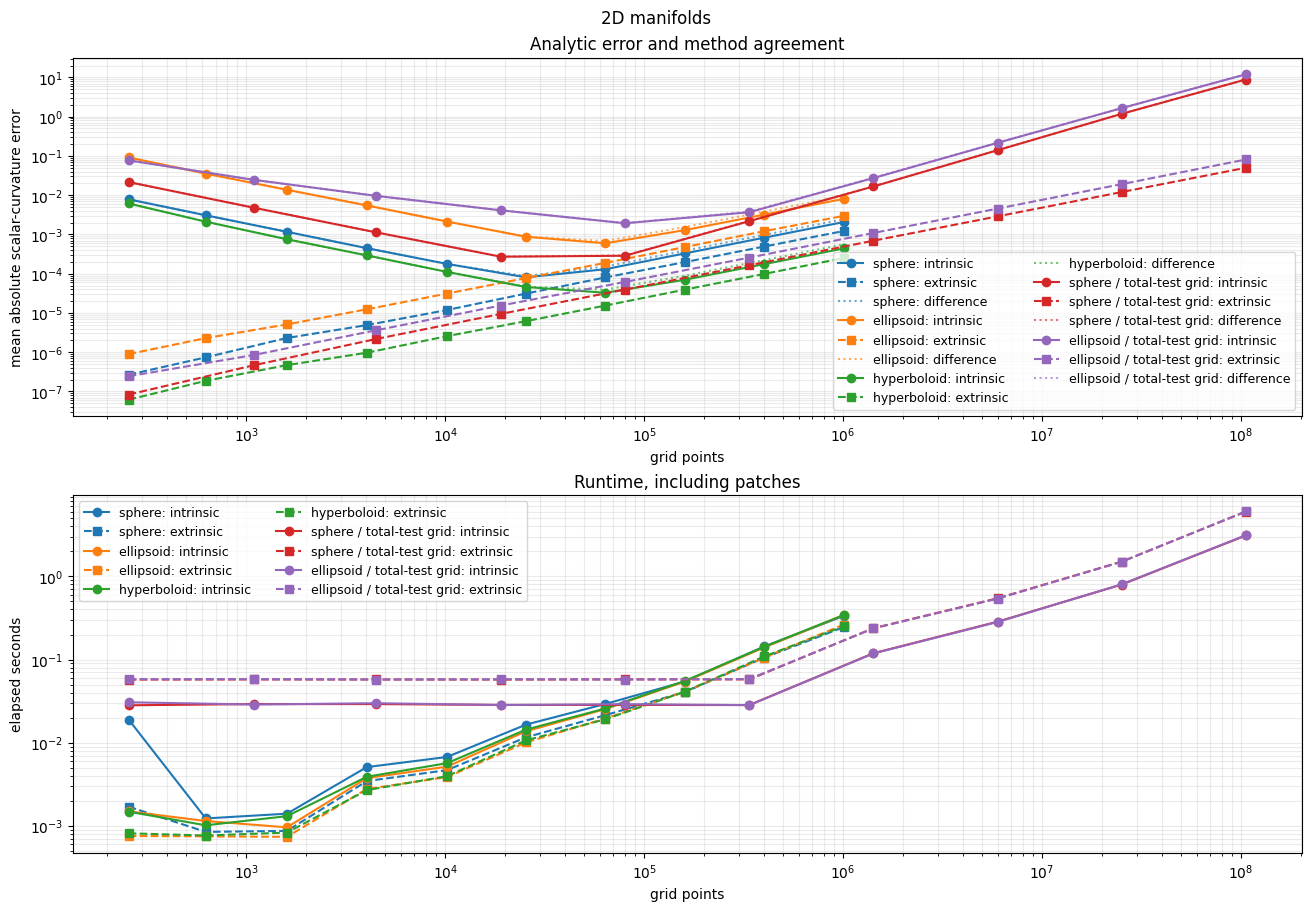

In [77]:
plot_results(results_2d, '2D manifolds');

## 3D and 4D manifolds (slow)

Run this section when ready for the slow grids. Select a subset with `SLOW_CASE_NAMES` in the setup.

In [78]:
results_slow = run_cases(SLOW_CASES)

Running 3D ellipsoid / ambient 4, (16, 16, 16): embedding alone 6.55e-05 GB
3D ellipsoid / ambient 4    (16, 16, 16)     intrinsic 0.0939  extrinsic 3.46e-06  difference 0.0939
Running 3D ellipsoid / ambient 4, (20, 20, 20): embedding alone 0.000128 GB
3D ellipsoid / ambient 4    (20, 20, 20)     intrinsic 0.056  extrinsic 4.69e-06  difference 0.056
Running 3D ellipsoid / ambient 4, (24, 24, 24): embedding alone 0.000221 GB
3D ellipsoid / ambient 4    (24, 24, 24)     intrinsic 0.0387  extrinsic 6.89e-06  difference 0.0387
Running 3D ellipsoid / ambient 4, (30, 30, 29): embedding alone 0.000418 GB
3D ellipsoid / ambient 4    (30, 30, 29)     intrinsic 0.0257  extrinsic 9.72e-06  difference 0.0257
Running 3D ellipsoid / ambient 4, (37, 37, 36): embedding alone 0.000789 GB
3D ellipsoid / ambient 4    (37, 37, 36)     intrinsic 0.0165  extrinsic 1.42e-05  difference 0.0165
Running 3D ellipsoid / ambient 4, (46, 46, 44): embedding alone 0.00149 GB
3D ellipsoid / ambient 4    (46, 46, 44)  

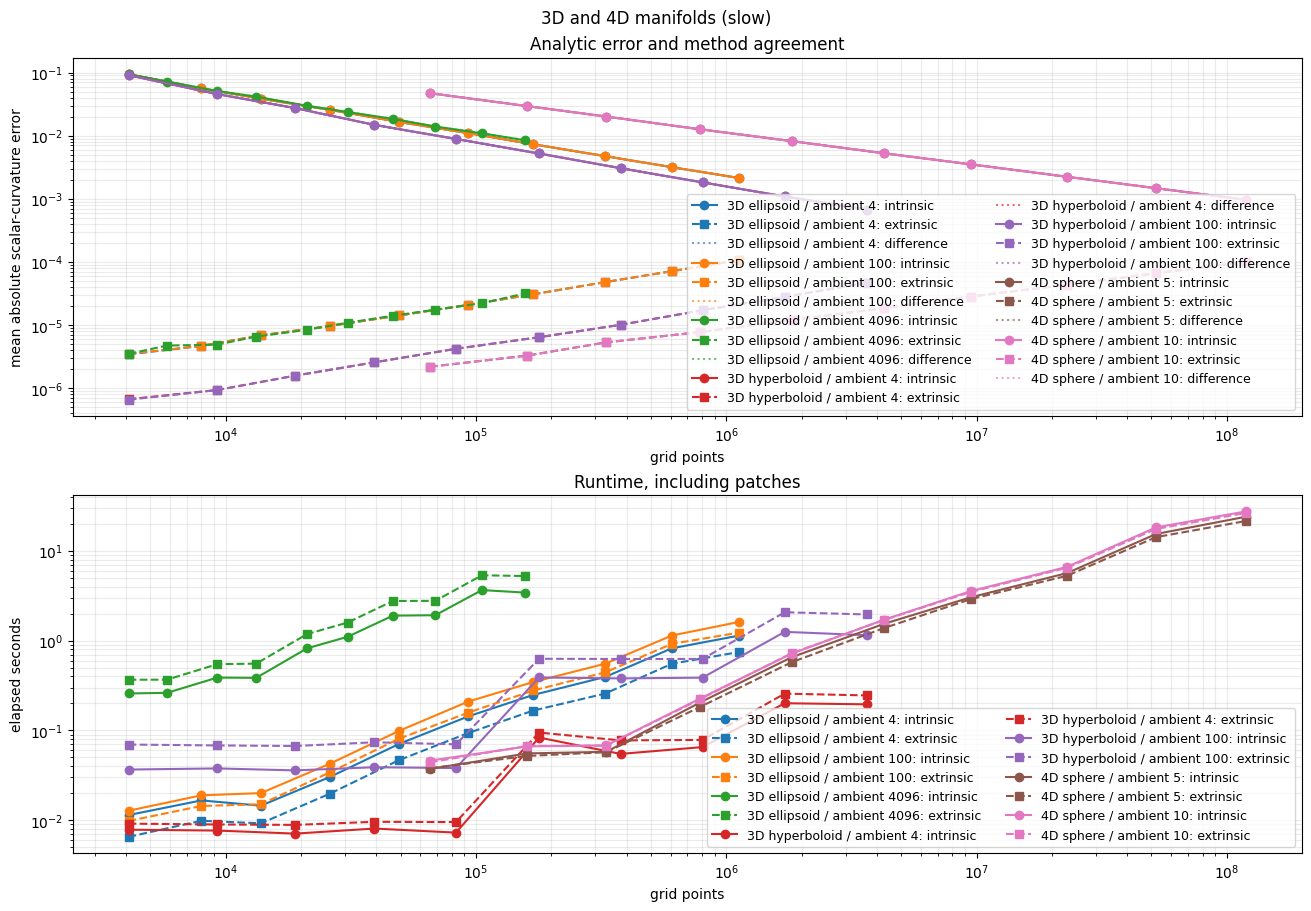

In [79]:
plot_results(results_slow, '3D and 4D manifolds (slow)');

## Quartic, Gaussian and rippled graphs

Generic 2D graphs for ordinary finite-difference convergence.

In [80]:
results_graphs = run_cases(GRAPH_CASES)

Running quartic, (16, 16): embedding alone 3.07e-06 GB
quartic                     (16, 16)         intrinsic 0.0504  extrinsic 0.0538  difference 0.0034
Running quartic, (24, 24): embedding alone 6.91e-06 GB
quartic                     (24, 24)         intrinsic 0.0226  extrinsic 0.0253  difference 0.00387
Running quartic, (35, 35): embedding alone 1.47e-05 GB
quartic                     (35, 35)         intrinsic 0.0107  extrinsic 0.0116  difference 0.00282
Running quartic, (51, 51): embedding alone 3.12e-05 GB
quartic                     (51, 51)         intrinsic 0.00515  extrinsic 0.00526  difference 0.0017
Running quartic, (75, 75): embedding alone 6.75e-05 GB
quartic                     (75, 75)         intrinsic 0.00243  extrinsic 0.00236  difference 0.000914
Running quartic, (110, 110): embedding alone 0.000145 GB
quartic                     (110, 110)       intrinsic 0.00114  extrinsic 0.00108  difference 0.000488
Running quartic, (161, 161): embedding alone 0.000311 GB
quart

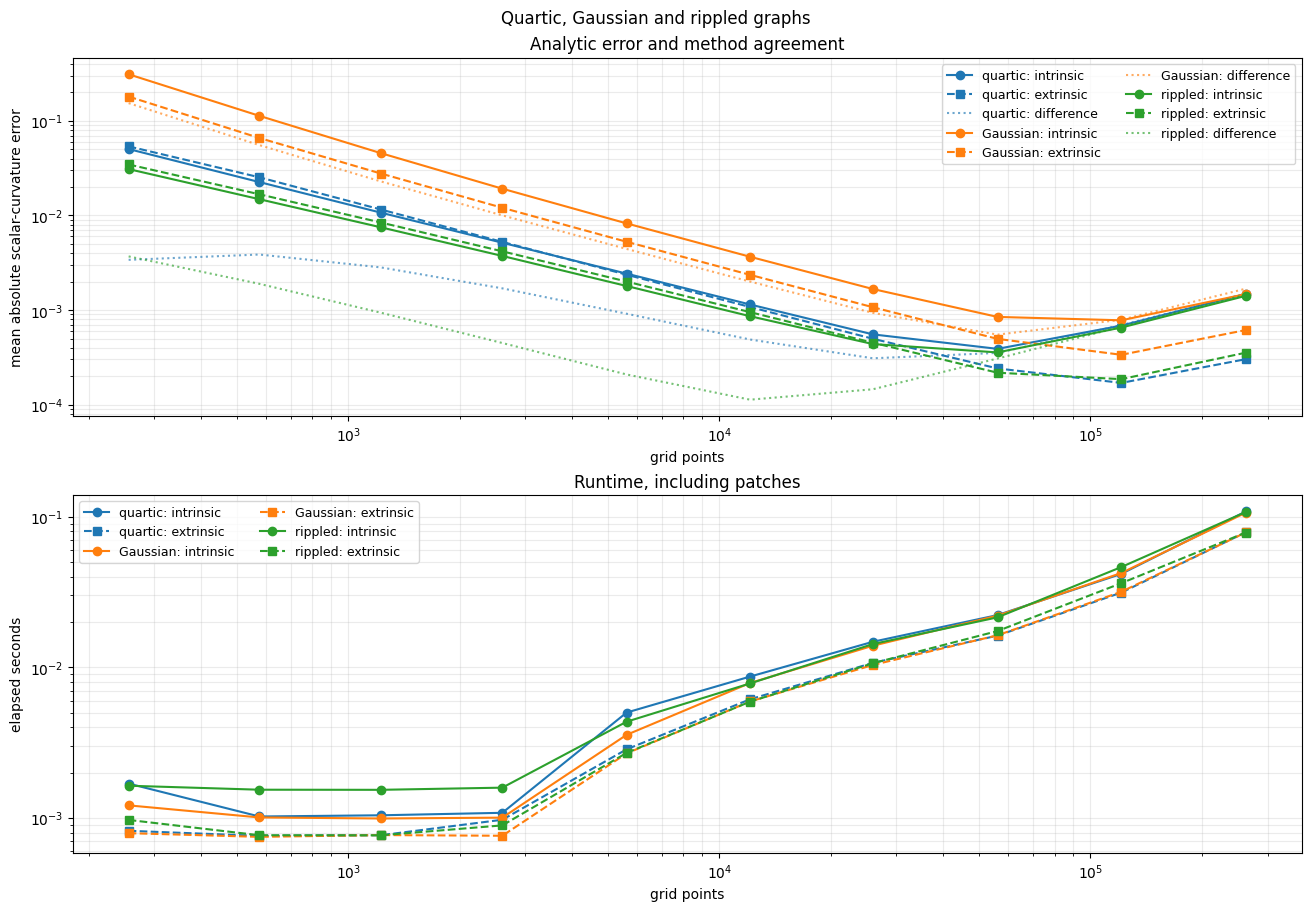

In [81]:
plot_results(results_graphs, 'Quartic, Gaussian and rippled graphs');

Check analytic errors before interpreting agreement between methods. These parameterizations are special for the extrinsic stencil: central differences of sin/cos multiply exact derivatives by `sin(h)/h`, and those of sinh/cosh by `sinh(h)/h`. Applying the same central difference twice gives the corresponding product of factors for second derivatives. Those factors cancel between the metric inverse and the second fundamental form in the Gauss contraction. In exact arithmetic, these ellipsoid, sphere and hyperboloid examples therefore have no truncation error with this stencil.

Their extrinsic errors largely measure floating-point roundoff, amplified approximately as `epsilon / h**2` by second differences (with geometry-dependent conditioning). Increasing density can increase this tiny error immediately. The intrinsic metric/Christoffel calculation does not share the cancellation, so its second-order truncation error initially decreases. It too eventually reaches a roundoff regime. Float64 is recommended; converting already rounded float32 samples back to float64 cannot recover lost information. Generic embeddings do not share this cancellation and should be tested separately for convergence.

Changing density also changes the retained nonperiodic domain because both methods crop three samples at each end. Near coordinate singularities, inspect maximum errors and conditioning as well as the mean. These plots alone cannot establish convergence on general manifolds.


For an ordinary convergence comparison, use the three graph cases in the final experiment section. The quartic graph is `z = 0.2*u**4 + 0.3*v**4 + 0.1*u*v`; the Gaussian bump is `z = 0.7*exp(-2*(u**2 + v**2))`; the rippled graph is `z = 0.2*sin(2*u) + 0.15*cos(3*v) + 0.1*u*v`. Their reference is `R = 2*(f_uu*f_vv - f_uv**2)/(1 + f_u**2 + f_v**2)**2`, using explicit analytic derivatives. The linear embedding coordinates `u,v` and nonlinear height do not share the quadric stencil factors. All three show decreasing errors in small CPU float64 checks at 16, 32, 64 and 128 samples per axis. No floating-point example avoids roundoff indefinitely; the 512 maximum is chosen to stay in the truncation-dominated range. On these nonperiodic grids, MAE also reflects the changing cropped domain; inspect convergence rates accordingly.


## Image datasets: full-dimensional pixel embeddings

Compare the balanced custom dSprites renderer (4 varying coordinates: size, rotation, y, x) and augmented COIL-20 (3: view, size, in-plane rotation). Every image retains all 64 × 64 = 4,096 pixel features; there is no PCA, latent projection or removal of varying coordinates. These are the same image families as `image_datasets.ipynb`, including dSprites blur sigma 0.8 and COIL's 18 original views. Images are mapped from [-1, 1] to [0, 1] once, before sub-gridding. Native rendered samples are float32; derivatives use `DTYPE` from the setup. Converting to float64 does not recover precision lost during rendering.

Each run selects regular strided sub-grids from one fixed parent grid, rather than regenerating images at each resolution. Spacings are the original spacings multiplied by stride; cyclic strides must divide the parent length so the seam has the same spacing. All classes are included by default, as disconnected components; no derivative crosses class boundaries. Each dataset has an independent run cell followed by a plot cell below. Run the shared setup at the top and these image helpers first; the earlier mathematical sweeps are not required.

The mean defaults to the arithmetic mean over all retained grid points (`IMAGE_WEIGHTING = "grid"`). Use `"volume"` for a Riemannian volume-weighted mean; weights are computed on each sub-grid and aligned to the curvature crop. Image scale is held fixed across resolutions; no per-resolution volume normalization is applied. Nonperiodic axes lose three samples at each end, so the evaluated domain grows as the stride decreases. This ablation therefore changes both spacing and the cropped domain.

The upper panel compares signed mean scalar curvature (circles intrinsic, squares extrinsic); the lower panel compares curvature computation time summed over the selected classes at each grid size. Timing includes the curvature method's patching, device transfers and computation, with CUDA synchronization at the timing boundaries. It excludes image generation/loading, sub-grid preparation, optional volume weights and mean aggregation. Failed method/resolution combinations leave gaps in both panels. No ground truth is assumed.

Full grids are large: one dSprites class is about 2.8 GB in float32; COIL-20 together is about 2.1 GB before working arrays. dSprites is generated one class at a time. Small patches limit derivative memory. Edit the class lists and stride schedules below to limit a run. COIL-20 uses the loader's `COIL20_PATH` environment variable, or its default `~/datasets/curvature-landscapes/coil-20-proc`; no download is performed. Singular metric failures and nonfinite values are reported and leave gaps in the affected mean, rather than silently dropping a class or points.


The extra distribution cell in each subsection has one row per grid size: left, normalized histogram estimates for intrinsic and extrinsic curvature overlaid using identical bins; right, the signed difference `intrinsic − extrinsic`. Differences are computed on matching retained coordinates within each class **before** pooling classes. All pointwise values and the matching weights are kept in the result, so bins can be changed without recomputing curvature. `IMAGE_DENSITY_BINS` controls the approximation; no tails are trimmed. A constant distribution is displayed as a finite-width histogram bin, not a continuous ground-truth density. The weighting matches `IMAGE_WEIGHTING`. Means alone from older runs cannot reconstruct these plots: rerun the image helper and dataset computation cells to retain pointwise samples.

`INCLUDE_DSPRITES_FULL_GRID = False` skips the all-strides-one dSprites computation by default, while retaining the coarser sub-grids. Set it to `True` and rerun the dSprites computation cell when you want the full grid included. The renderer still creates the same parent grid so all sub-grid comparisons use the same images. Mean/runtime plots remain available alongside the new distribution plots.


In [82]:
from microscope.datasets import custom_dsprites, coil20
from microscope.computations_grid.volume import volume_element

IMAGE_WEIGHTING = "grid"  # "grid" or "volume" weighting for the mean.
INCLUDE_DSPRITES_FULL_GRID = True  # Set True to include the expensive all-strides-one run.
IMAGE_DENSITY_BINS = 60  # Normalized histogram estimate; common bins for both methods.
DSPRITES_CLASSES = None  # None = square, ellipse, heart; or e.g. ["heart"].
COIL20_CLASSES = None  # None = all 20 objects; or e.g. ["duck", "cat"].
# Axis order: (size, rotation, y, x), and (view, size, in-plane rotation).
DSPRITES_STRIDES = [(3, 2, 3, 3), (2, 2, 2, 2), (1, 2, 1, 1), (1, 1, 1, 1)]
COIL20_STRIDES = [(2, 3, 2), (2, 2, 2), (1, 2, 1), (1, 1, 1)]
IMAGE_PATCH_SIZES = {"dsprites": [10]*4, "coil20": [10]*3}


In [83]:
def image_class_grids(dataset, class_names=None):
    """Yield one component, fixed parent grid, spacings and periodic axes."""
    mapping = custom_dsprites.LABEL_MAPPING if dataset == "dsprites" else coil20.LABEL_MAPPING
    names = list(mapping.values()) if class_names is None else list(class_names)
    if not names or len(set(names)) != len(names) or not set(names) <= set(mapping.values()):
        raise ValueError(f"Select distinct classes from {list(mapping.values())}")
    if dataset == "dsprites":
        for name in names:
            # Exact balanced-renderer parameters, one class at a time to bound memory.
            images, _ = custom_dsprites.dsprites(
                image_size=64, sprite_initial_size=20, deformation_transforms_initial_size_factor=4,
                sprites=(name,), n_sizes=22, n_angles=16, min_size_ratio=.5, max_size_ratio=1.,
                max_translation=22, translation_stride=2, blur_sigma=.8,
                flat=False, scale=False, dtype=np.float32, processes=[None]*4, verbose=False)
            images = images[0]
            images += 1.
            images *= .5
            shape = images.shape[:-2]
            intervals = get_difference_intervals(list(shape), [1., 2*np.pi, 1., 1.], [1])
            yield name, images.reshape((*shape, 4096)), intervals, [1]
            del images
    elif dataset == "coil20":
        images, _ = coil20.extended_coil20(flat=False, scale=False,
                                          buffer_for_measure_estimation=3, verbose=False)
        images += 1.
        images *= .5
        shape = images.shape[1:-2]
        intervals = get_difference_intervals(list(shape), [2*np.pi, 1., 2*np.pi], [0, 2])
        for label, name in mapping.items():
            if name in names:
                yield name, images[label].reshape((*shape, 4096)), intervals, [0, 2]
    else:
        raise ValueError(f"Unknown image dataset: {dataset}")


def image_subgrid(grid, intervals, cyclic, strides):
    dim = grid.ndim - 1
    if len(strides) != dim or len(intervals) != dim:
        raise ValueError("One stride and spacing is required per varying grid coordinate.")
    for axis, stride in enumerate(strides):
        if not isinstance(stride, (int, np.integer)) or stride < 1:
            raise ValueError("Strides must be positive integers.")
        if axis in cyclic and grid.shape[axis] % stride:
            raise ValueError(f"Stride {stride} must divide periodic axis length {grid.shape[axis]}.")
        if len(range(0, grid.shape[axis], stride)) < 7:
            raise ValueError("Every sampled axis needs at least seven points for curvature.")
    selection = tuple(slice(None, None, int(s)) for s in strides) + (slice(None),)
    # No feature subsampling. Only this selected grid is promoted to computation dtype.
    points = np.ascontiguousarray(grid[selection], dtype=DTYPE)
    return points, [float(h*s) for h, s in zip(intervals, strides)]


def image_curvature_summary(values, weights):
    """Compute a finite weighted mean without dropping invalid points."""
    values, weights = np.asarray(values).ravel(), np.asarray(weights).ravel()
    if values.size == 0 or values.shape != weights.shape:
        raise ValueError("Values and weights must be nonempty and aligned.")
    if (not np.isfinite(values).all() or not np.isfinite(weights).all()
            or np.any(weights < 0) or not np.any(weights > 0)):
        raise FloatingPointError("Nonfinite curvature/weights or invalid volume weights.")
    return dict(mean=float(np.average(values, weights=weights)),
                samples=int(np.count_nonzero(weights > 0)))


def run_image_comparison(dataset, strides, class_names=None, device=DEVICE,
                         weighting=IMAGE_WEIGHTING, class_grids=None):
    if weighting not in ("grid", "volume"):
        raise ValueError("weighting must be 'grid' or 'volume'")
    strides = [tuple(s) for s in strides]
    if not strides or len(set(strides)) != len(strides):
        raise ValueError("Provide a nonempty schedule of distinct strides.")
    methods = (("intrinsic", intrinsic_curvature), ("extrinsic", extrinsic_curvature))
    buckets = [dict(strides=s, grid_points=0, classes=[], shapes=[],
                    values={m: [] for m, _ in methods}, weights={m: [] for m, _ in methods},
                    differences=[], difference_weights=[], difference_errors=[], curvature_shapes=[],
                    errors={m: [] for m, _ in methods}, seconds={m: 0. for m, _ in methods})
               for s in strides]
    components = image_class_grids(dataset, class_names) if class_grids is None else class_grids
    for name, grid, intervals, cyclic in components:
        for bucket in buckets:
            points, spacing = image_subgrid(grid, intervals, cyclic, bucket["strides"])
            bucket["classes"].append(name)
            bucket["shapes"].append(points.shape[:-1])
            bucket["grid_points"] += int(np.prod(points.shape[:-1]))
            kwargs = dict(difference_intervals=spacing, cyclic_dimensions=cyclic,
                          patch_sizes=IMAGE_PATCH_SIZES[dataset], device=device)
            print(f"{dataset} / {name}: strides {bucket['strides']}, grid {points.shape[:-1]}, "
                  f"all {points.shape[-1]} pixels, {points.nbytes/1e9:.3g} GB", flush=True)
            weights = None
            if weighting == "volume":
                volume = volume_element(points, **kwargs)
                align = tuple(slice(None) if axis in cyclic else slice(2, -2)
                              for axis in range(points.ndim - 1))
                # Constant coordinate-cell factor matters when pooling different components.
                weights = volume[align] * np.prod(spacing)
            predictions = {}
            expected_shape = tuple(n if axis in cyclic else n - 6
                                   for axis, n in enumerate(points.shape[:-1]))
            bucket["curvature_shapes"].append(expected_shape)
            for label, method in methods:
                if str(device).startswith("cuda"):
                    torch.cuda.synchronize(device)
                start = perf_counter()
                try:
                    try:
                        prediction = method(points, **kwargs)
                    finally:
                        if str(device).startswith("cuda"):
                            torch.cuda.synchronize(device)
                        bucket["seconds"][label] += perf_counter() - start
                    if prediction.shape != expected_shape:
                        raise ValueError("Curvature output does not align with the sampled coordinate grid.")
                    sample_weights = np.ones_like(prediction) if weights is None else weights
                    if prediction.shape != sample_weights.shape:
                        raise ValueError("Volume weights and curvature crops do not align.")
                    # Fail visibly on any nonfinite result; don't trim tails or drop components.
                    image_curvature_summary(prediction, sample_weights)
                    predictions[label] = prediction
                    bucket["values"][label].append(prediction.ravel())
                    bucket["weights"][label].append(sample_weights.ravel())
                except (torch.linalg.LinAlgError, FloatingPointError) as error:
                    message = f"{name}: {type(error).__name__}: {error}"
                    bucket["errors"][label].append(message)
                    print(f"  {label} FAILED: {message}", flush=True)
            if len(predictions) == 2:
                # Subtract matched coordinates within this class, before any pooling.
                difference = predictions["intrinsic"] - predictions["extrinsic"]
                difference_weights = np.ones_like(difference) if weights is None else weights
                bucket["differences"].append(difference.ravel())
                bucket["difference_weights"].append(difference_weights.ravel())
            else:
                bucket["difference_errors"].append(f"{name}: both curvature methods must succeed for paired differences.")
            del points
        del grid  # Release the previous component before requesting the next one.
    rows = []
    for bucket in sorted(buckets, key=lambda b: b["grid_points"]):
        if not bucket["classes"]:
            raise ValueError("No image classes were provided.")
        row = {key: bucket[key] for key in ("strides", "grid_points", "classes", "shapes", "curvature_shapes")}
        for label, _ in methods:
            errors = bucket["errors"][label]
            if errors:
                values, weights = np.empty(0), np.empty(0)
                summary = dict(mean=np.nan, samples=0)
            else:
                values = np.concatenate(bucket["values"][label])
                weights = np.concatenate(bucket["weights"][label])
                summary = image_curvature_summary(values, weights)
            row[label] = dict(**summary, values=values, weights=weights,
                              errors=errors, seconds=bucket["seconds"][label])
        errors = bucket["difference_errors"]
        if errors:
            values, weights = np.empty(0), np.empty(0)
            summary = dict(mean=np.nan, samples=0)
        else:
            values = np.concatenate(bucket["differences"])
            weights = np.concatenate(bucket["difference_weights"])
            summary = image_curvature_summary(values, weights)
        row["signed_difference"] = dict(**summary, values=values, weights=weights, errors=errors)
        rows.append(row)
    return dict(dataset=dataset, rows=rows, difference_definition="intrinsic - extrinsic",
                weighting=weighting, dtype=np.dtype(DTYPE).name, device=str(device))



def plot_image_comparison(result):
    rows = result["rows"]
    if not rows:
        raise ValueError("Run this dataset comparison before plotting.")
    x = np.asarray([row["grid_points"] for row in rows])
    fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True, constrained_layout=True)
    for method, marker, linestyle in (("intrinsic", "o", "-"), ("extrinsic", "s", "--")):
        style = dict(color="C0", marker=marker, linestyle=linestyle, label=method)
        means = [row[method]["mean"] for row in rows]
        seconds = [row[method]["seconds"] if not row[method]["errors"] else np.nan for row in rows]
        axes[0].plot(x, means, **style)
        axes[1].plot(x, seconds, **style)
    axes[0].set(title=f"Mean scalar curvature ({result['weighting']} weighting)", ylabel="mean scalar curvature")
    axes[0].axhline(0., color="0.5", linewidth=.7, alpha=.4)
    axes[1].set(title="Curvature computation time, including patches and device transfers",
                ylabel="elapsed seconds (all selected classes)")
    for ax in axes:
        ax.set_xlabel("sampled grid points (all selected classes)")
        ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
        ax.grid(True, alpha=.2)
        ax.legend()
    fig.suptitle(f"{result['dataset']}: full-dimensional image grids")
    failures = sum(bool(row[m]["errors"]) for row in rows for m in ("intrinsic", "extrinsic"))
    if failures:
        print(f"{failures} method/resolution combinations failed: gaps are retained; inspect result['rows'].")
    plt.show()
    return fig



def image_density_estimate(values, weights, edges):
    """Normalized weighted histogram: the area under the density is one."""
    image_curvature_summary(values, weights)  # Validate every point and weight.
    return np.histogram(values, bins=edges, weights=weights, density=True)[0]


def plot_image_pointwise_distributions(result, bins=IMAGE_DENSITY_BINS):
    rows = result["rows"]
    if not rows:
        raise ValueError("Run this dataset comparison before plotting.")
    if any("values" not in row[method] for row in rows for method in ("intrinsic", "extrinsic")):
        raise ValueError("Pointwise samples are missing. Rerun this dataset's computation cell with the updated image helpers.")
    fig, axes = plt.subplots(len(rows), 2, figsize=(14, 3.5*len(rows)),
                             squeeze=False, constrained_layout=True)
    for (curvature_ax, difference_ax), row in zip(axes, rows):
        available = [row[m]["values"] for m in ("intrinsic", "extrinsic") if len(row[m]["values"])]
        # Shared bin edges within each resolution make the overlay comparable.
        edges = np.histogram_bin_edges(np.concatenate(available), bins=bins) if available else None
        for method, linestyle in (("intrinsic", "-"), ("extrinsic", "--")):
            data = row[method]
            if len(data["values"]):
                density = image_density_estimate(data["values"], data["weights"], edges)
                curvature_ax.stairs(density, edges, color="C0", linestyle=linestyle,
                                    linewidth=1.6, label=method)
            else:
                curvature_ax.plot([], [], color="C0", linestyle=linestyle, label=f"{method}: unavailable")
        difference = row["signed_difference"]
        if len(difference["values"]):
            edges = np.histogram_bin_edges(difference["values"], bins=bins)
            density = image_density_estimate(difference["values"], difference["weights"], edges)
            difference_ax.stairs(density, edges, color="C1", linewidth=1.6,
                                 label="intrinsic − extrinsic")
        else:
            difference_ax.text(.5, .5, "Paired difference unavailable: a computation failed",
                               ha="center", va="center", transform=difference_ax.transAxes)
        difference_ax.axvline(0., color="0.4", linestyle=":", linewidth=1.)
        count = f"{row['grid_points']:,} input grid points; strides {row['strides']}"
        curvature_ax.set(title=count, xlabel="scalar curvature", ylabel="estimated probability density")
        difference_ax.set(title=f"Signed pointwise differences ({difference['samples']:,} points with positive weight)",
                          xlabel="intrinsic scalar curvature − extrinsic scalar curvature",
                          ylabel="estimated probability density")
        curvature_ax.legend()
        if len(difference["values"]):
            difference_ax.legend()
        for ax in (curvature_ax, difference_ax):
            ax.grid(True, alpha=.2)
    fig.suptitle(f"{result['dataset']}: pointwise curvature distributions ({result['weighting']} weighting)")
    plt.show()
    return fig


### dSprites: 4D, all 4,096 pixels

Generate one class at a time, then compare the selected sub-grids.

In [ ]:
# Filter by stride rather than position, so custom schedules also respect the switch.
dsprites_strides_to_run = [
    strides for strides in DSPRITES_STRIDES
    if INCLUDE_DSPRITES_FULL_GRID or any(stride != 1 for stride in strides)
]
results_dsprites = run_image_comparison(
    "dsprites", dsprites_strides_to_run, class_names=DSPRITES_CLASSES)

dsprites / square: strides (3, 2, 3, 3), grid (8, 8, 8, 8), all 4096 pixels, 0.0671 GB
dsprites / square: strides (2, 2, 2, 2), grid (11, 8, 11, 11), all 4096 pixels, 0.174 GB
dsprites / square: strides (1, 2, 1, 1), grid (22, 8, 22, 22), all 4096 pixels, 1.4 GB
dsprites / square: strides (1, 1, 1, 1), grid (22, 16, 22, 22), all 4096 pixels, 2.79 GB
dsprites / ellipse: strides (3, 2, 3, 3), grid (8, 8, 8, 8), all 4096 pixels, 0.0671 GB
dsprites / ellipse: strides (2, 2, 2, 2), grid (11, 8, 11, 11), all 4096 pixels, 0.174 GB
dsprites / ellipse: strides (1, 2, 1, 1), grid (22, 8, 22, 22), all 4096 pixels, 1.4 GB
dsprites / ellipse: strides (1, 1, 1, 1), grid (22, 16, 22, 22), all 4096 pixels, 2.79 GB


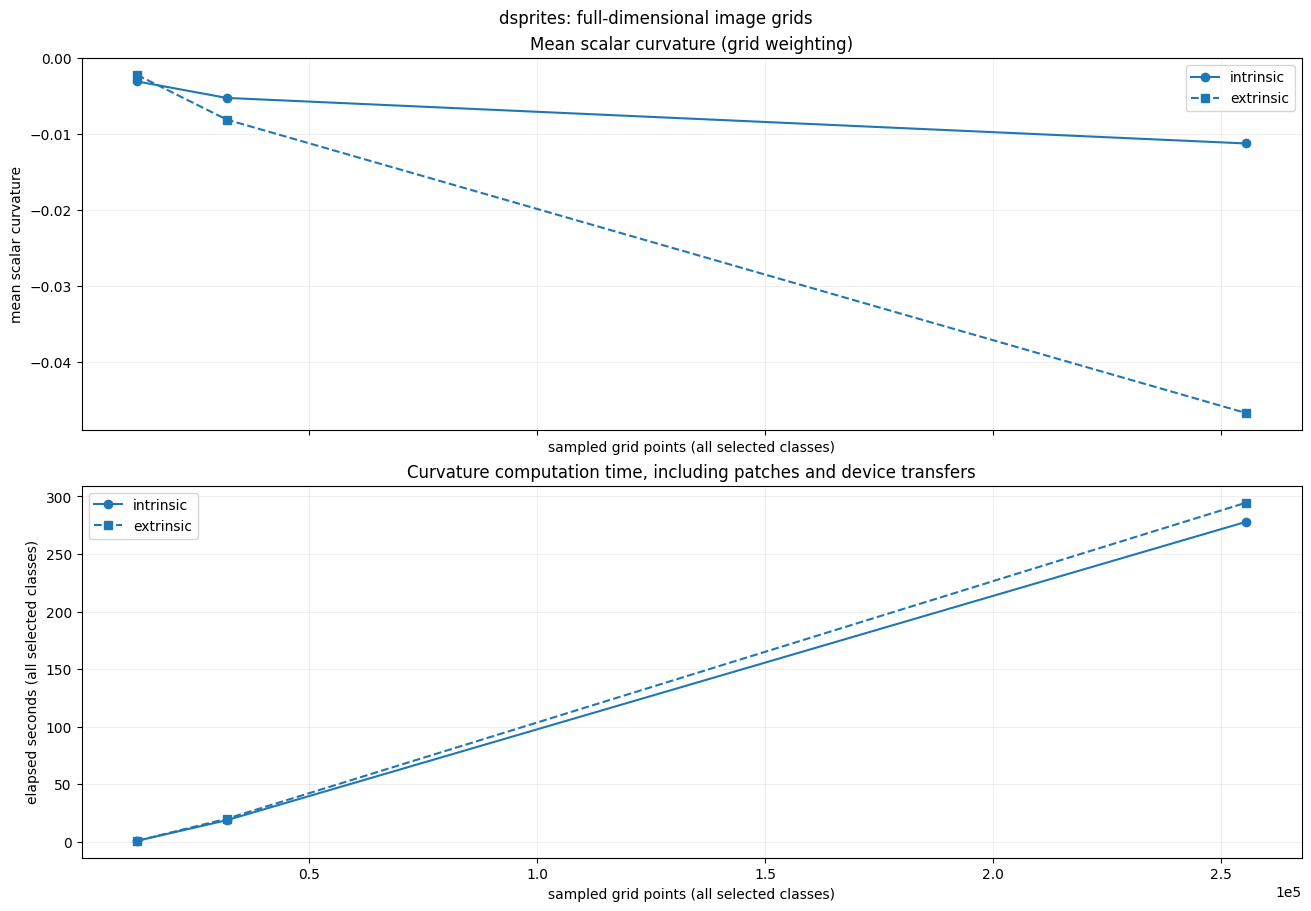

In [ ]:
plot_image_comparison(results_dsprites);

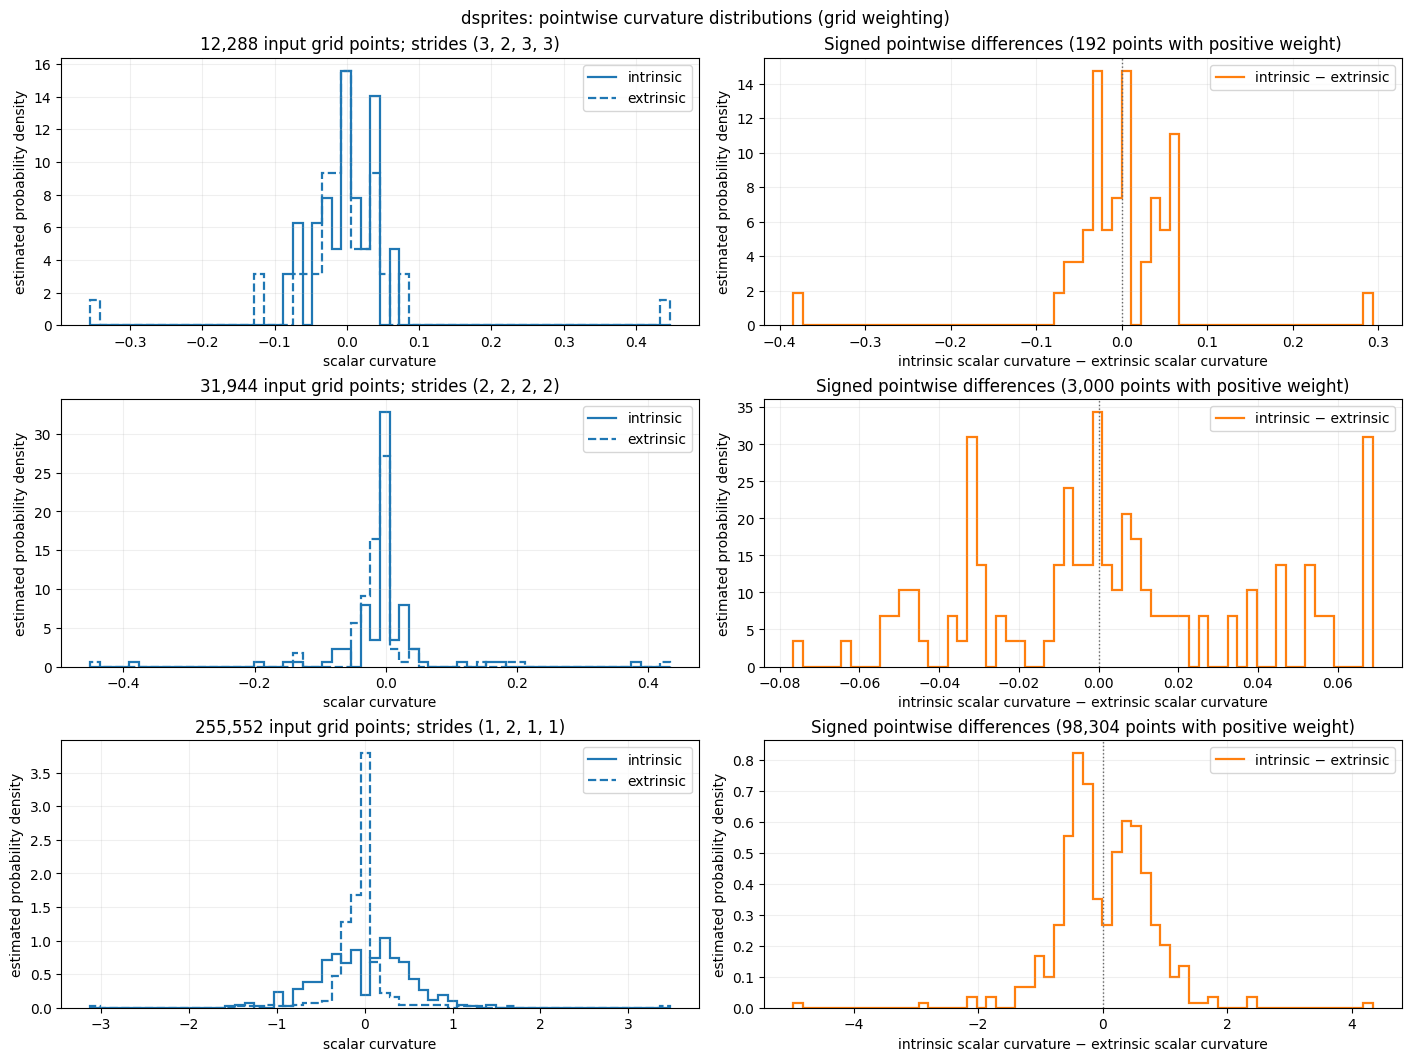

In [ ]:
plot_image_pointwise_distributions(results_dsprites);

### COIL-20: 3D, all 4,096 pixels

Load the existing processed images and augment view, size and in-plane rotation.

In [67]:
results_coil20 = run_image_comparison(
    "coil20", COIL20_STRIDES, class_names=COIL20_CLASSES)

coil20 / duck: strides (2, 3, 2), grid (9, 8, 8), all 4096 pixels, 0.0189 GB
coil20 / duck: strides (2, 2, 2), grid (9, 11, 8), all 4096 pixels, 0.026 GB
coil20 / duck: strides (1, 2, 1), grid (18, 11, 16), all 4096 pixels, 0.104 GB
coil20 / duck: strides (1, 1, 1), grid (18, 22, 16), all 4096 pixels, 0.208 GB
coil20 / wood_triangle: strides (2, 3, 2), grid (9, 8, 8), all 4096 pixels, 0.0189 GB
coil20 / wood_triangle: strides (2, 2, 2), grid (9, 11, 8), all 4096 pixels, 0.026 GB
coil20 / wood_triangle: strides (1, 2, 1), grid (18, 11, 16), all 4096 pixels, 0.104 GB
coil20 / wood_triangle: strides (1, 1, 1), grid (18, 22, 16), all 4096 pixels, 0.208 GB
coil20 / car0: strides (2, 3, 2), grid (9, 8, 8), all 4096 pixels, 0.0189 GB
coil20 / car0: strides (2, 2, 2), grid (9, 11, 8), all 4096 pixels, 0.026 GB
coil20 / car0: strides (1, 2, 1), grid (18, 11, 16), all 4096 pixels, 0.104 GB
coil20 / car0: strides (1, 1, 1), grid (18, 22, 16), all 4096 pixels, 0.208 GB
coil20 / cat: strides (2, 3,

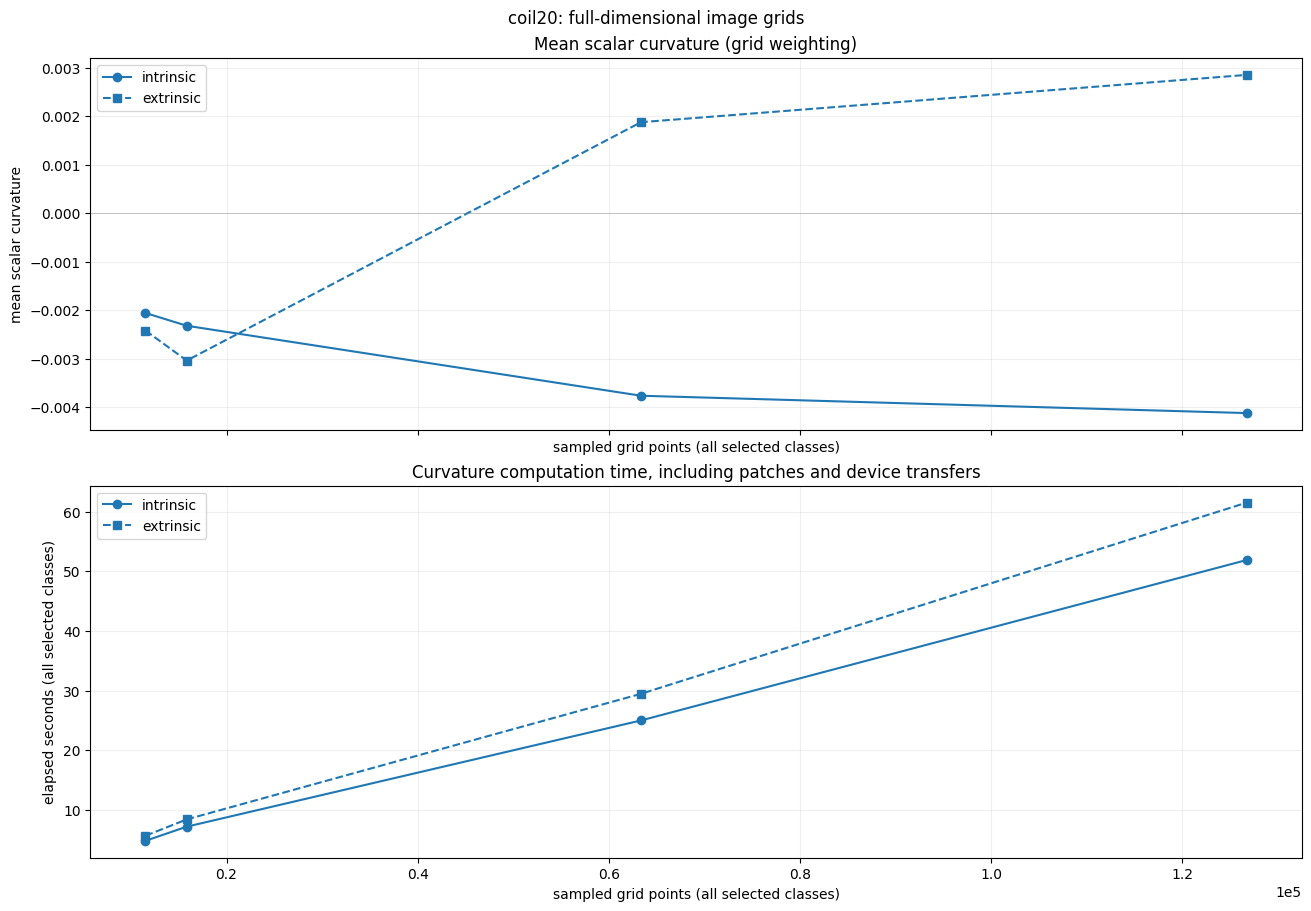

In [68]:
plot_image_comparison(results_coil20);

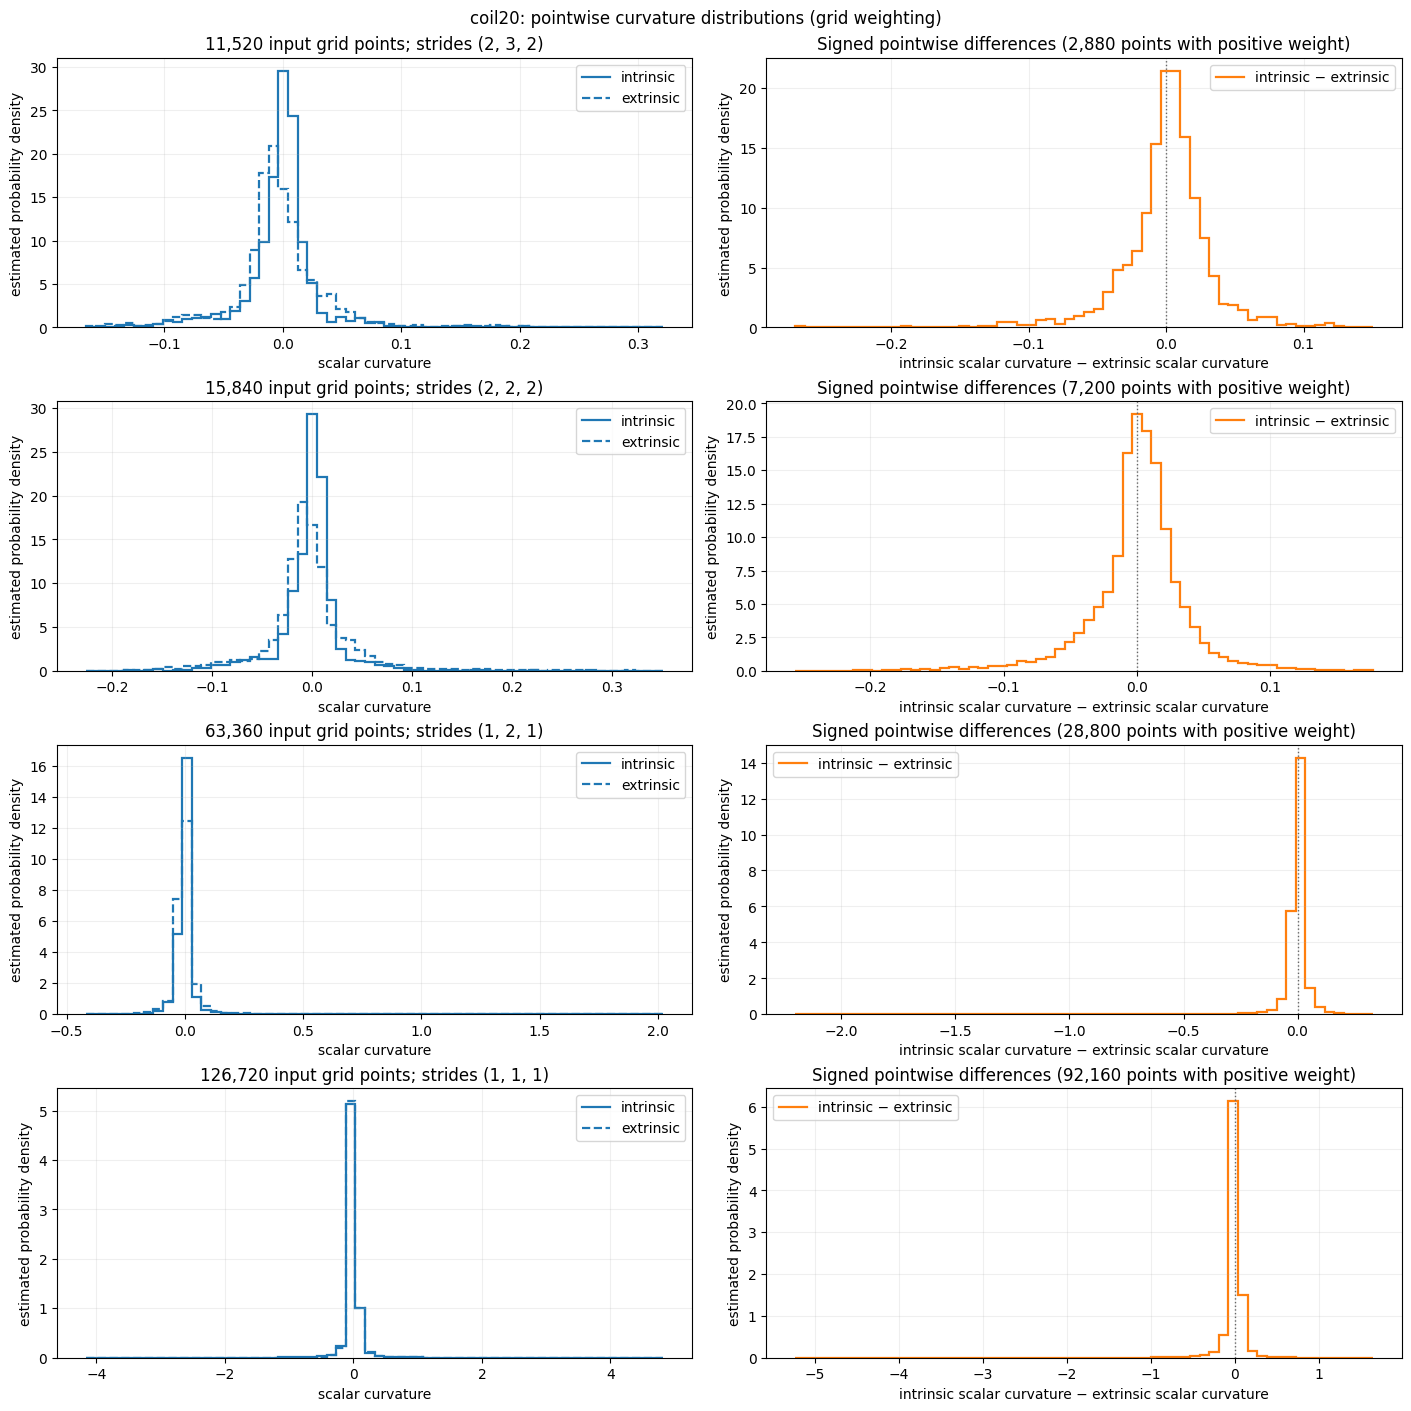

In [69]:
plot_image_pointwise_distributions(results_coil20);